In [1]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

True
Tesla T4


In [1]:
!git clone https://github.com/asn104610/WBC-Differentiator-v.1.git /content/repo
!ls /content/repo


Cloning into '/content/repo'...
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 19 (delta 3), reused 13 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (19/19), 766.78 KiB | 3.04 MiB/s, done.
Resolving deltas: 100% (3/3), done.
01_explore_data.ipynb  LICENSE		 test.csv
01_setup_check.ipynb   README.md	 train.csv
02_split_data.ipynb    requirements.txt  val.csv


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!mkdir -p /content/data
!unzip -q "/content/drive/MyDrive/WBC-project/PBC_dataset_normal_DIB.zip" -x "__MACOSX/*" -d /content/data
!ls /content/data
!ls /content/data/PBC_dataset_normal_DIB

unzip:  cannot find or open /content/drive/MyDrive/WBC-project/PBC_dataset_normal_DIB.zip, /content/drive/MyDrive/WBC-project/PBC_dataset_normal_DIB.zip.zip or /content/drive/MyDrive/WBC-project/PBC_dataset_normal_DIB.zip.ZIP.
ls: cannot access '/content/data/PBC_dataset_normal_DIB': No such file or directory


In [4]:
!ls "/content/drive/MyDrive/WBC-Folder"

PBC_dataset_normal_DIB.zip


In [5]:
!mkdir -p /content/data
!unzip -q "/content/drive/MyDrive/WBC-Folder/PBC_dataset_normal_DIB.zip" -x "__MACOSX/*" -d /content/data
!ls /content/data/PBC_dataset_normal_DIB

basophil    erythroblast  lymphocyte  neutrophil
eosinophil  ig		  monocyte    platelet


In [6]:
import pandas as pd, os

!git clone https://github.com/asn104610/WBC-Differentiator-v.1.git /content/repo

root = "/content/data/PBC_dataset_normal_DIB"

def fix_path(p, label):
    name = p.replace("\\", "/").split("/")[-1]
    return f"{root}/{label}/{name}"

def load_split(name):
    d = pd.read_csv(f"/content/repo/{name}.csv")
    d["path"] = [fix_path(p, l) for p, l in zip(d["path"], d["label"])]
    return d

train_df = load_split("train")
val_df = load_split("val")
test_df = load_split("test")

print("train:", len(train_df), "val:", len(val_df), "test:", len(test_df))
print("all files found:", all(os.path.exists(p) for p in pd.concat([train_df, val_df, test_df])["path"]))

fatal: destination path '/content/repo' already exists and is not an empty directory.
train: 11964 val: 2564 test: 2564
all files found: True


In [7]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

classes = sorted(train_df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class CellDataset(Dataset):
    def __init__(self, d):
        self.paths = d["path"].tolist()
        self.labels = [class_to_idx[l] for l in d["label"]]
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return tfm(img), self.labels[i]

train_loader = DataLoader(CellDataset(train_df), batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(CellDataset(val_df), batch_size=64, shuffle=False, num_workers=2)
print(classes)

['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


In [8]:
device = "cuda"
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(3):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()

    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    print(f"epoch {epoch+1}: val accuracy = {correct/len(val_df):.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


epoch 1: val accuracy = 0.972
epoch 2: val accuracy = 0.963
epoch 3: val accuracy = 0.981


              precision    recall  f1-score   support

    basophil      0.963     0.989     0.976       182
  eosinophil      1.000     1.000     1.000       468
erythroblast      0.991     0.970     0.980       232
          ig      0.974     0.940     0.957       435
  lymphocyte      0.968     1.000     0.984       182
    monocyte      0.963     0.991     0.977       213
  neutrophil      0.972     0.978     0.975       499
    platelet      1.000     1.000     1.000       353

    accuracy                          0.981      2564
   macro avg      0.979     0.983     0.981      2564
weighted avg      0.981     0.981     0.981      2564



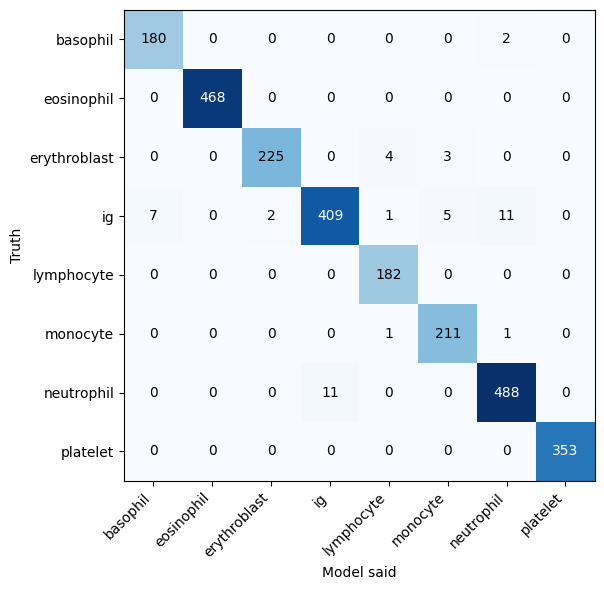

In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

model.eval()
preds, truths = [], []
with torch.no_grad():
    for x, y in val_loader:
        out = model(x.to(device)).argmax(1).cpu()
        preds += out.tolist()
        truths += y.tolist()

print(classification_report(truths, preds, target_names=classes, digits=3))

cm = confusion_matrix(truths, preds)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(8)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(8)); ax.set_yticklabels(classes)
for i in range(8):
    for j in range(8):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Model said")
ax.set_ylabel("Truth")
plt.tight_layout()
plt.show()

In [10]:
torch.save(model.state_dict(), "/content/drive/MyDrive/WBC-Folder/resnet18_wbc_v1.pt")
print("model saved")

model saved
